![Your First Trace in Langfuse](assets/banner-02.svg)

In notebook 01 we created a trace, but it only lived inside the notebook. Now we send it to **Langfuse**, a free, open source tool that stores traces and shows them in a dashboard.

**Why Langfuse?** It is built for AI apps. Without any extra work it records the prompt, the AI's answer, the model name, the number of tokens and the cost of every AI call. You can run it on your own laptop, which we do here.

### Before you start

Langfuse must be running. From the project folder:

```bash
make up
```

Then open **http://localhost:3000** and sign in with `admin@observability.lab` / `observability123`.

## Step 1: Connect to Langfuse

Langfuse needs three settings, which are already in the `.env` file:

| Setting | Value | What it is |
|---|---|---|
| `LANGFUSE_BASE_URL` | `http://localhost:3000` | Where Langfuse is running |
| `LANGFUSE_PUBLIC_KEY` | `pk-lf-...` | Like a username for your project |
| `LANGFUSE_SECRET_KEY` | `sk-lf-...` | Like a password for your project |

You find the keys in the Langfuse web page under **Settings, API Keys**.

In [1]:
from dotenv import load_dotenv

load_dotenv("../.env")

from langfuse import get_client

langfuse = get_client()
print("Connected to Langfuse:", langfuse.auth_check())

Connected to Langfuse: True


## Step 2: Add Langfuse to the weather assistant

This is the same assistant as notebook 01. Only **two things** changed, marked with `# NEW`:

1. We import `OpenAI` from `langfuse.openai` instead of `openai`. This version records every AI call automatically: prompt, answer, model, tokens and cost.
2. We put `@observe()` above each function. Each decorated function becomes a span. Functions called inside other functions become child spans, exactly like the `with` blocks in notebook 01.

In [2]:
import time

from langfuse import observe
from langfuse.openai import OpenAI  # NEW: records every AI call

client = OpenAI()

FAKE_WEATHER = {"Paris": "rainy, 14°C", "Tokyo": "sunny, 21°C", "London": "stormy, 11°C", "Dubai": "hot and dry, 35°C"}


@observe()  # NEW: this function becomes a span
def get_weather(city):
    time.sleep(0.5)
    return FAKE_WEATHER[city]


@observe()  # NEW
def ask_ai(question):
    reply = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[{"role": "user", "content": question}],
    )
    return reply.choices[0].message.content


@observe()  # NEW: the outer function becomes the whole trace
def weather_assistant(city):
    weather = get_weather(city)
    question = f"The weather in {city} is {weather}. Should I carry an umbrella? Answer in one short sentence."
    return ask_ai(question)

## Step 3: Run it

In [3]:
print(weather_assistant("Paris"))
print(weather_assistant("Dubai"))

langfuse.flush()  # send everything to Langfuse now (important in notebooks and short scripts)

Yes, you should carry an umbrella.


No, you don't need to carry an umbrella in dry weather.


## Step 4: Look at the trace

Open **http://localhost:3000**, click **Tracing** in the left menu, and click the newest `weather_assistant` trace.

Here is the same trace, fetched from Langfuse and drawn in the notebook:

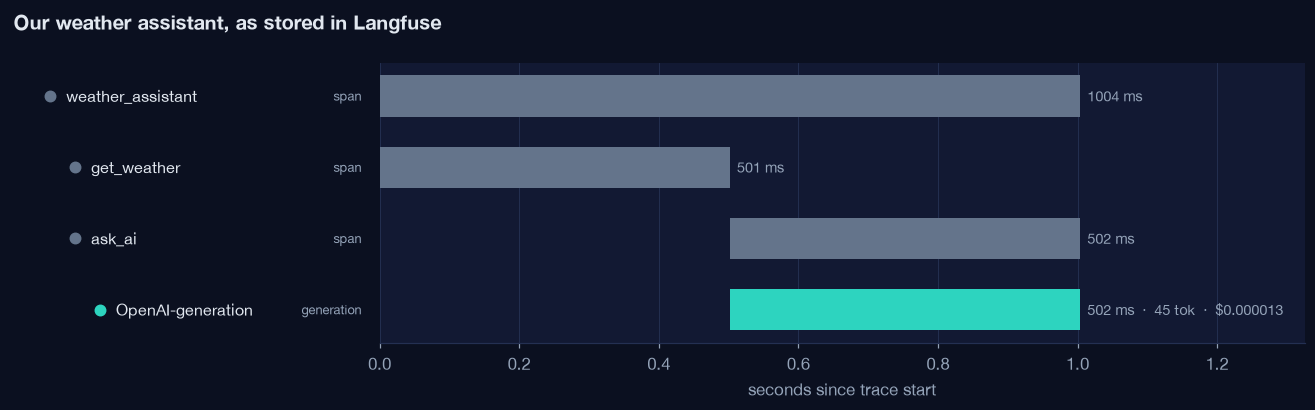

Open in Langfuse: http://localhost:3000/project/weather-agent/traces/54139285c6a486bb0e95ccfb26832197


In [4]:
import lab

time.sleep(3)  # give Langfuse a moment to process
latest = lab.langfuse_observations(limit=5, name="weather_assistant").sort_values("startTime")["traceId"].iloc[-1]
lab.show_trace(latest, "Our weather assistant, as stored in Langfuse");
print("Open in Langfuse:", langfuse.get_trace_url(trace_id=latest))

Notice the extra row we did not write ourselves: **`OpenAI-generation`**. That is the AI call, recorded by the `langfuse.openai` import, with its token count and cost in dollars.

### What to click in Langfuse

| Click on | You will see |
|---|---|
| `weather_assistant` | The input (`"Paris"`), the final answer, and the total time |
| `get_weather` | Its input and output, and that it took about 0.5 seconds |
| `OpenAI-generation` | The exact prompt sent, the AI's reply, the model, tokens and cost |
| The **Timeline** view | The same bars as the picture above |

## Step 5 (optional): Who asked?

In a real app you want to know **which user** made a request, so you can find their traces when they complain. One `with` block adds a user id to every span inside it.

In [5]:
from langfuse import propagate_attributes

with propagate_attributes(user_id="ana@example.com"):
    print(weather_assistant("London"))

langfuse.flush()

Yes, you should carry an umbrella.


In Langfuse, click **Users** in the left menu. You will find `ana@example.com` with her traces, tokens and cost.

## Recap

| What we did | Code |
|---|---|
| Connected to Langfuse | three settings in `.env` |
| Recorded every AI call | `from langfuse.openai import OpenAI` |
| Turned functions into spans | `@observe()` |
| Sent the data | `langfuse.flush()` |

That is the whole integration. Behind the scenes Langfuse uses **OpenTelemetry**, the same standard we used in notebook 01.

**Next:** [03 LangSmith](03_langsmith.ipynb). The same assistant in a different tool.